In [ ]:
### Learnt new

# .transform -> comme un OVER (PARTITION BY)
    df_reviews = pd.read_csv("../data/raw/reviews.csv", parse_dates=["date"])
    df["year_total"] = (
        df
        .groupby("year")["n_reviews"]
        .transform("sum")
    )

# .all() 
   assert np.isclose(table_to_check["pct_of_year"],100,atol=0.15).all() # -> The order is always: compare first, then reduce

# Percentiles 
    df["price_eur"].quantile([0.5, 0.9, 0.99])

# Save list of indexes: .index save indexes, .tolist() turns them into a list
    .index
    .tolist()

### LINE CHART
    import matplotlib.pyplot as plt # -> the engine: 
    import seaborn as sns           # -> You give it a long DataFrame and column names, and it handles the grouping
    wide_df.plot() # Si wide dataset ? 

    fig, ax = plt.subplots(figsize=(10, 5))                                 # always start with fig, ax = plt.subplots().
    sns.lineplot(data=<long_df>, x="<col>", y="<col>", hue="<col>", ax=ax)  # hue -> le grouping 
    ax.set_title("<the answer, as a sentence>")
    ax.set_xlabel("<label>")
    ax.set_ylabel("<label>")
    fig.text(0.01, -0.02, "Note: ...", fontsize=9)  # 0.01 et -0.02 : position dans le cadre du graphe
    fig.savefig("../docs/<name>.png", dpi=150, bbox_inches="tight")

### HISTOGRAM
    sns.histplot(data=df, x="price_eur", bins=50, ax=ax)

### BOX PLOT 
    sns.boxplot(data=df, x="room_type", y="price_eur", ax=ax, order=...)
    # -> order=.. should be a list of the category

### BAR CHART 
    sns.barplot(data=..., x="median_price", y="neighbourhood_cleansed", ax=ax, order=...)
    ax.axvline(value, linestyle="--", color="grey") # -> vertical dsahed line 
    # -> same as box plot for the order; or order the data just before doing the graph

# Which chart to use:
    # line for change over time;
    # bar to compare categories;
    # histogram/box plot for a distribution;
        # histogram is better for one group in detail
        # box plot to compare a distibution across groups
    # scatter for the relationship between two numeric variables.



In [ ]:
### Task 1: the seasonality chart

import pandas as pd 
df_reviews = pd.read_csv("../data/raw/reviews.csv", parse_dates=["date"])
df_reviews["year"]=df_reviews["date"].dt.year
df_reviews["month"]=df_reviews["date"].dt.month
df_reviews=df_reviews.loc[(df_reviews["year"].between(2022,2025)) | ((df_reviews["year"]==2026) & (df_reviews["month"]<9)) ]

df_long = (
    df_reviews
    .groupby(["year", "month"], as_index=False)
    .agg(n_reviews = ("listing_id","count"))
)

import matplotlib.pyplot as plt
import seaborn as sns   
fig, ax = plt.subplots(figsize=(10, 5))                                 
sns.lineplot(data=df_long, x="month", y="n_reviews", hue="year", ax=ax) 
ax.set_title("June and October peaks, Jan.2022 - Aug.2026")
ax.set_xlabel("Month")
ax.set_ylabel("Number of reviews")
fig.text(0.01, -0.02,"Note: (i) data for September 2026 is partially missing so it is excluded (ii) data for October-December 2026 is entirely missing.", fontsize=9)
fig.savefig("../docs/fig_reviews_seasonality.png", dpi=150, bbox_inches="tight")

In [ ]:
### Task 2: compare the shapes, not the levels

import pandas as pd 
df_reviews = pd.read_csv("../data/raw/reviews.csv", parse_dates=["date"])
df_reviews["year"]=df_reviews["date"].dt.year
df_reviews["month"]=df_reviews["date"].dt.month
df_reviews=df_reviews.loc[(df_reviews["year"].between(2022,2025)) | ((df_reviews["year"]==2026) & (df_reviews["month"]<9)) ]

# Long table for charts
df_long = (
    df_reviews
    .groupby(["year", "month"], as_index=False)
    .agg(n_reviews = ("listing_id","count"))
)

# Keep complete years only 
df_long = df_long.loc[df_long.groupby("year")["month"].transform("count")==12]

# Month's share of its year's review
df_long["pct_of_year"]=(
    df_long["n_reviews"]
    / (df_long.groupby("year")["n_reviews"].transform("sum"))
).mul(100)

# Checks 
table_to_check = df_long.groupby("year", as_index=False)["pct_of_year"].sum()
display(table_to_check)
import numpy as np 
assert np.isclose(table_to_check["pct_of_year"],100,atol=0.15).all() 

# Charts 
import matplotlib.pyplot as plt
import seaborn as sns   
fig, ax = plt.subplots(figsize=(10, 5))                                 
sns.lineplot(data=df_long, x="month", y="pct_of_year", hue="year", ax=ax) 
ax.set_title("Reviews peak in June and October every year (2022–2025)")
ax.set_xlabel("Month")
ax.set_ylabel("Share of reviews (%)")
fig.text(0.01, -0.02,"Note: 2026 data is excluded because it is incomplete.", fontsize=9)
fig.savefig("../docs/fig_reviews_seasonality_shares.png", dpi=150, bbox_inches="tight")

# 25min

In [ ]:
### Task 3: the price distribution

import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns   
df = pd.read_parquet("../data/clean/listings_clean.parquet") 
df = df.loc[df["price_eur"].notna()]

# 1. Percentiles 
display(df["price_eur"].quantile([0.01, 0.25, 0.50, 0.75, 0.9, 0.99, 0.999, 1]))
p99=df["price_eur"].quantile(0.99)

# Prepare data for graphs 
df_no99=df.copy()
df_no99=df_no99.loc[df_no99["price_eur"]<=p99]
listings_p99=(len(df.loc[df["price_eur"]>p99]))

# 2. Histogram 
fig, ax = plt.subplots(figsize=(10,5))
sns.histplot(data=df_no99, x="price_eur", bins=50, ax=ax)
ax.set_title("Right skewed price distribution")
ax.set_xlabel("Price (€)")
ax.set_ylabel("Number of listings")
fig.text(0.00, -0.015, f"Note: listings with prices above the 99th percentile are excluded ({listings_p99} listings).")
fig.savefig("../docs/fig_price_histogram.png", dpi=150, bbox_inches="tight")

# 3. Box plot 

# Get price median order by room type 
order_by_median = (
    df_no99
    .groupby("room_type")["price_eur"]
    .median()
    .sort_values(ascending=False)
    .index
    .tolist()
)

fig, ax = plt.subplots(figsize=(10,5))
sns.boxplot(data=df_no99, x="price_eur", y="room_type", ax=ax, order=order_by_median)
ax.set_title("Least to most expensive room types")
ax.set_xlabel("Price (€)")
ax.set_ylabel("Room type")
fig.text(0.00, -0.015, f"Note: listings with prices above the 99th percentile are excluded ({listings_p99} listings).")
fig.savefig("../docs/fig_price_boxplot.png", dpi=150, bbox_inches="tight")

In [ ]:
### Bar chart by neighbourhood

import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns   
df = pd.read_parquet("../data/clean/listings_clean.parquet") 
df = df.loc[(df["price_eur"].notna()) & (df["room_type"]=="Entire home/apt")]

median_entire_homes = df["price_eur"].median()
table = (
    df 
    .groupby("neighbourhood_cleansed")
    .agg(
        nb_listings = ("id","size"),
        median_price = ("price_eur", "median")
    )
    .sort_values("median_price", ascending=False)
)

fig, ax = plt.subplots(figsize=(10,5))
sns.barplot(data=table, x="median_price", y="neighbourhood_cleansed", ax=ax)
ax.axvline(median_entire_homes, linestyle="--", color="grey")
ax.set_title("Most (Élysée) to least (Ménilmontant) expensive neighbourhoods, entire homes only")
ax.set_xlabel("Median price (€)")
ax.set_ylabel("Neighbourhood")
ax.text(median_entire_homes+3,len(table)-1,"Paris-wide median for entire homes")
fig.savefig("../docs/fig_price_bar_chart.png", dpi=150, bbox_inches="tight")


,accommodates,price_per_guest_median,nb_listings
0,1,69.330000,1412
1,2,80.500000,30000
2,3,65.333333,5945
3,4,65.125000,19693
4,5,70.000000,2844
5,6,73.393333,5667
6,7,72.428571,627
7,8,78.268125,1366
8,9,87.228333,118
9,10,77.800000,378


ValueError: Could not interpret value `price_per_guest` for `y`. An entry with this name does not appear in `data`.

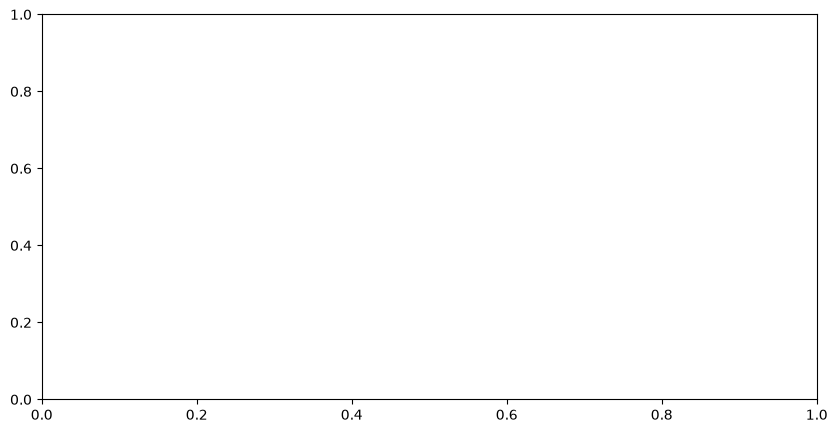

In [ ]:
### Task 5: your first AI audit drill

# Using listings_clean.parquet, show whether bigger entire homes are cheaper per guest, and write a one-line conclusion.

df = pd.read_parquet("../data/clean/listings_clean.parquet")
homes = df[df["room_type"] == "Entire home/apt"]
homes["price_per_guest"] = homes["price_eur"] / homes["accommodates"]

summary = (
    homes.groupby("accommodates")
    .agg(
        price_per_guest_median = ("price_per_guest","median"),
        nb_listings = ("id", "size")
    )
    .reset_index()
)
display(summary)
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=summary, x="accommodates", y="price_per_guest", ax=ax)
ax.set_title("Larger homes are more expensive per guest")
ax.set_ylabel("Median price per guests (€)")
fig.savefig("../docs/fig_price_per_guest_median.png")